# Cross-Lingual Post-`</think>` Residual Similarity Plots

This notebook loads and visualizes the cross-lingual transported residual cosine similarity results from `data/experiments/multilang/crosslingual_think_similarity.csv`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="talk", palette="deep")

### Helper functions

In [2]:
# def extract_answer(df):
#     """Extract the answer the model gave when asked to choose an option"""
#     df['answer_1'] = df['full_prompt_1'].str[-2]
#     df['answer_2'] = df['full_prompt_2'].str[-2]
#     df['same_answer'] = df['answer_1'] == df['answer_2']


In [48]:
# MODEL_NAME = "Qwen3.5-4B"
MODEL_NAME = "gemma-4-E4B-it"

# MODEL_NAME="gemma-3-27b-it"
# MODEL_NAME ="Qwen3.6-27B"

# Plots

In [49]:
# Read the original CSV file containing crosslingual similarity data
folder = f"data/experiments/multilang/{MODEL_NAME}"
df_original = pd.read_csv(f"{folder}/baseline.csv")
# df_original = pd.read_csv(f"{folder}/baseline_ no_single.csv")

print(f"Loaded {len(df_original):,} rows across {df_original['slug'].nunique()} scenarios and layers: {sorted(df_original['layer'].unique())}")

# extract_answer(df_original)
df_original.head()

Loaded 9,702 rows across 294 scenarios and layers: [np.int64(21), np.int64(23), np.int64(25), np.int64(27), np.int64(29), np.int64(31), np.int64(33), np.int64(35), np.int64(37), np.int64(39), np.int64(41)]


,slug,scenario,lang_1,lang_2,same_language,sample_id,layer,pos_1,pos_2,token_1,...,top_k_overlap_count,top_k_overlap_ratio,raw_top_k_overlap_count,raw_top_k_overlap_ratio,top_k_tokens_1,top_k_tokens_2,shared_top_k_tokens,raw_top_k_tokens_1,raw_top_k_tokens_2,raw_shared_top_k_tokens
0,Reddit_id_100,English/English,English,English,True,0,21,137,137,\n,...,10,1.0,10,1.0,"["" lựa"", ""Choice"", "" decisión"", "" Choice"", ""ch...","["" lựa"", ""Choice"", "" decisión"", "" Choice"", ""ch...","["" lựa"", ""Choice"", "" decisión"", "" Choice"", ""ch...","["" boot"", "" breadth"", "" bung"", "" günlük"", ""kun...","["" boot"", "" breadth"", "" bung"", "" günlük"", ""kun...","["" boot"", "" breadth"", "" bung"", "" günlük"", ""kun..."
1,Reddit_id_100,English/English,English,English,True,0,23,137,137,\n,...,10,1.0,10,1.0,"[""opponent"", ""conven"", ""arbit"", ""enough"", ""Joh...","[""opponent"", ""conven"", ""arbit"", ""enough"", ""Joh...","[""opponent"", ""conven"", ""arbit"", ""enough"", ""Joh...","["" mence"", ""üler"", ""дора"", ""Das"", ""รา"", ""earch...","["" mence"", ""üler"", ""дора"", ""Das"", ""รา"", ""earch...","["" mence"", ""üler"", ""дора"", ""Das"", ""รา"", ""earch..."
2,Reddit_id_100,English/English,English,English,True,0,25,137,137,\n,...,10,1.0,10,1.0,"[""Neither"", "" Neither"", ""Both"", "" Both"", ""Desp...","[""Neither"", "" Neither"", ""Both"", "" Both"", ""Desp...","[""Neither"", "" Neither"", ""Both"", "" Both"", ""Desp...","[""psr"", "" камер"", ""するため"", ""kod"", ""uca"", ""𝑘"", ""...","[""psr"", "" камер"", ""するため"", ""kod"", ""uca"", ""𝑘"", ""...","[""psr"", "" камер"", ""するため"", ""kod"", ""uca"", ""𝑘"", ""..."
3,Reddit_id_100,English/English,English,English,True,0,27,137,137,\n,...,10,1.0,10,1.0,"[""Neither"", ""Either"", ""neither"", ""either"", ""Bo...","[""Neither"", ""Either"", ""neither"", ""either"", ""Bo...","[""Neither"", ""Either"", ""neither"", ""either"", ""Bo...","["" 為"", ""人員"", "" 電"", "" 個"", "" 機械"", "" سيكون"", ""彎"",...","["" 為"", ""人員"", "" 電"", "" 個"", "" 機械"", "" سيكون"", ""彎"",...","["" 為"", ""人員"", "" 電"", "" 個"", "" 機械"", "" سيكون"", ""彎"",..."
4,Reddit_id_100,English/English,English,English,True,0,29,137,137,\n,...,10,1.0,10,1.0,"[""第二"", "" second"", "" tweede"", ""②"", ""2"", "" deuxi...","[""第二"", "" second"", "" tweede"", ""②"", ""2"", "" deuxi...","[""第二"", "" second"", "" tweede"", ""②"", ""2"", "" deuxi...","["" seconde"", "" second"", ""第二"", ""second"", "" الثا...","["" seconde"", "" second"", ""第二"", ""second"", "" الثا...","["" seconde"", "" second"", ""第二"", ""second"", "" الثا..."


In [5]:
# Summary statistics by layer and same_language
# Define the custom order for scenarios
scenario_order = ["English/English", "Spanish/Spanish", "English/Spanish"] 
# Note: I adjusted "English/Spanish" to match standard naming, 
# please ensure these strings match your actual data exactly.

df_original['scenario'] = pd.Categorical(df_original['scenario'], categories=scenario_order, ordered=True)

summary_df = (
    df_original.groupby(["layer", "scenario"], as_index=False)["cosine_similarity"]
    .agg(mean="mean", std="std", count="count")
    .sort_values(["scenario", "layer"], ascending=[True, True])
    .round(4)
)
summary_df

/var/folders/gf/xjh2d0s55750j8jcclfdlf840000gn/T/ipykernel_74761/803419224.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_original.groupby(["layer", "scenario"], as_index=False)["cosine_similarity"]


,layer,scenario,mean,std,count
0,21,English/English,1.0000,0.0000,294
3,23,English/English,1.0000,0.0000,294
6,25,English/English,1.0000,0.0000,294
9,27,English/English,1.0000,0.0000,294
12,29,English/English,1.0000,0.0000,294
15,31,English/English,1.0000,0.0000,294
18,33,English/English,1.0000,0.0000,294
21,35,English/English,1.0000,0.0000,294
24,37,English/English,1.0000,0.0000,294
27,39,English/English,1.0000,0.0000,294


### Barplot: Cosine Similarity by Layer and language (same language/different language)

In [28]:
def plot(df, title=None, plot_legend=True):
    fig, ax = plt.subplots(figsize=(12, 6))

    sns.barplot(
        data=df,
        x="layer",
        y="cosine_similarity",
        hue="scenario",
        hue_order=["English/English", "Spanish/Spanish", "English/Spanish"],
        errorbar="sd",
        capsize=0.1,
        ax=ax,
    )
    
    ax.set_title(title or f"Transported Residual Cosine Similarity by Layer.\n{MODEL_NAME}. Original English lens.")
    ax.set_xlabel("Layer")
    ax.set_ylabel("Cosine Similarity")
    ax.set_ylim(0.75, 1.05)
    
    if plot_legend:
        ax.legend(title="Scenario", loc="upper left", bbox_to_anchor=(1, 1))
    elif ax.get_legend() is not None:
        ax.get_legend().remove()
    
    plt.tight_layout()
    plt.show()


### Baseline case

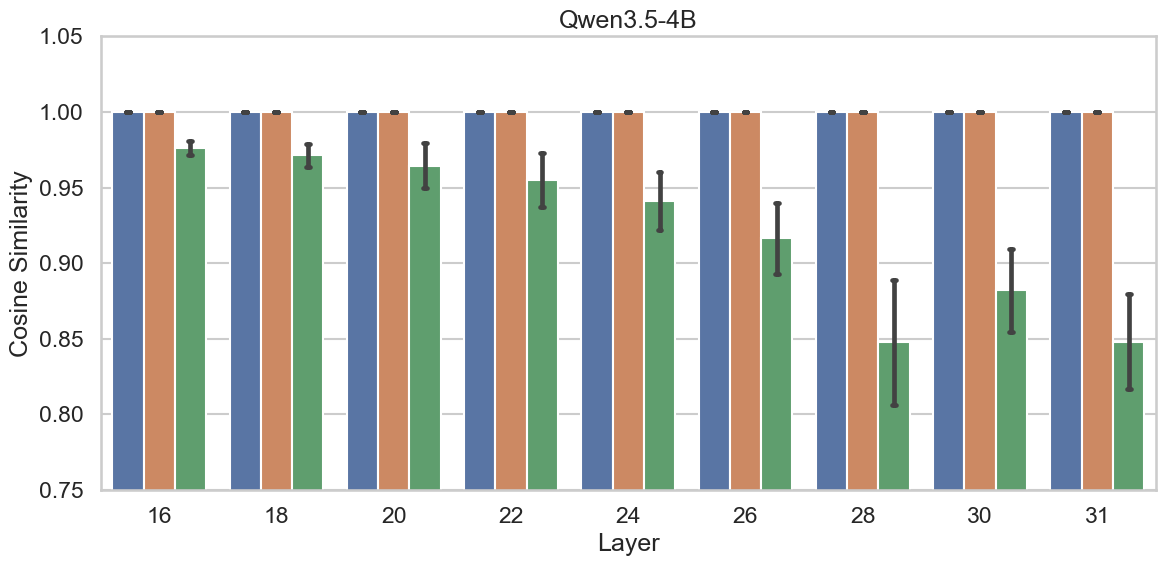

Saved plot to data/experiments/multilang/Qwen3.5-4B/baseline_plot.png


<Figure size 640x480 with 0 Axes>

In [29]:
# plot(df_original, plot_legend=False, title=F"Transported Residual Cosine Similarity by Layer.\n\n{MODEL_NAME}")
plot(df_original, plot_legend=False, title=F"{MODEL_NAME}")
# Save
p = f"{folder}/baseline_plot.png"
plt.savefig(p)
print(f"Saved plot to {p}")

## Extended Thinking case

In [7]:
# Read the extended Thinking scenario
df_original_extended = pd.read_csv(f"{folder}/thinking.csv")

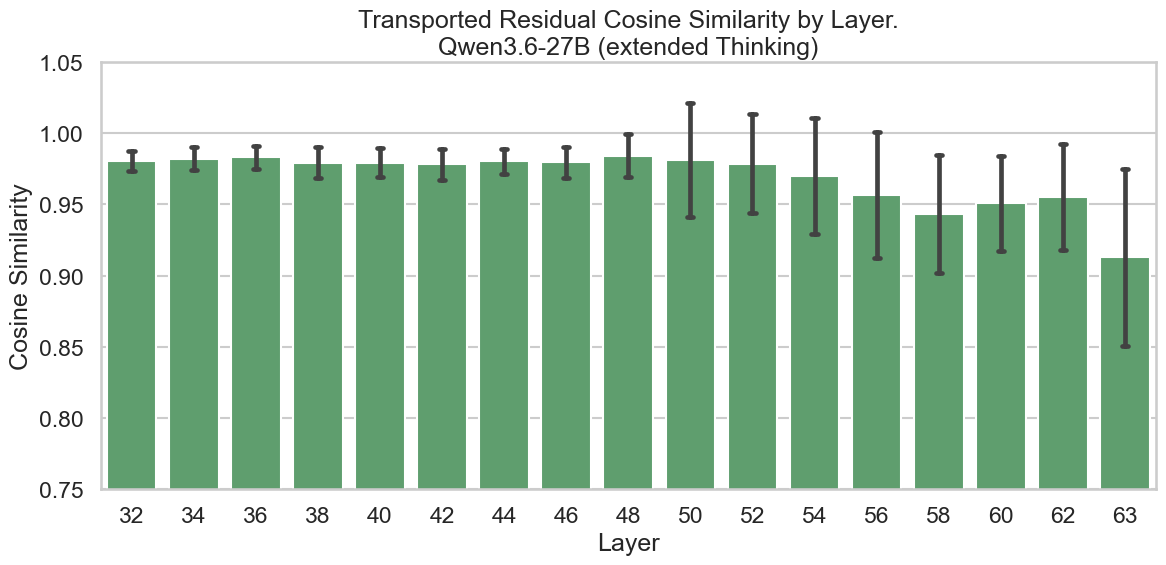

In [8]:
plot(df_original_extended, title=f"Transported Residual Cosine Similarity by Layer.\n{MODEL_NAME} (extended Thinking)", plot_legend=False)

In [10]:
# Combine the numbers of the baseline and the long term Thinking with the short term one
columns = [
    'slug',
    'scenario',
    'layer',
    'cosine_similarity',
    'Reasoning'
]
# Select only the multilangual scenario
df1 = df_original[df_original['scenario'] == 'English/Spanish'].copy()
# df1 = pd.read_csv(f"{folder}/single_shared_layers.csv")
df1['Reasoning'] = 'No'

df2 = df_original_extended.copy()
df2['Reasoning'] = 'Yes'

# Filter only the shared layers
# Hack for layers for now (substract 1 to layer index, since it's not expected to change much)
max_layer = df1['layer'].max()

print(df1['layer'].unique())

# df1['layer'] = df1['layer'].apply(lambda l: l + 1 if l < max_layer else l)
print(df2['layer'].unique())
layers_extended = df2['layer'].unique()
df1 = df1[df1['layer'].isin(layers_extended)]


# Combine short term and long term Thinking data
df_combined = pd.concat([df1[columns], df2[columns]], ignore_index=True)
df_combined

[32 34 36 38 40 42 44 46 48 50 52 54 56 58 60 62 63]
[32 34 36 38 40 42 44 46 48 50 52 54 56 58 60 62 63]


,slug,scenario,layer,cosine_similarity,Reasoning
0,Reddit_id_100,English/Spanish,32,0.977969,No
1,Reddit_id_100,English/Spanish,34,0.973432,No
2,Reddit_id_100,English/Spanish,36,0.973611,No
3,Reddit_id_100,English/Spanish,38,0.971405,No
4,Reddit_id_100,English/Spanish,40,0.973076,No
...,...,...,...,...,...
5078,short_id_9_MJI_Moral,English/Spanish,56,0.962099,Yes
5079,short_id_9_MJI_Moral,English/Spanish,58,0.948402,Yes
5080,short_id_9_MJI_Moral,English/Spanish,60,0.955078,Yes
5081,short_id_9_MJI_Moral,English/Spanish,62,0.956753,Yes


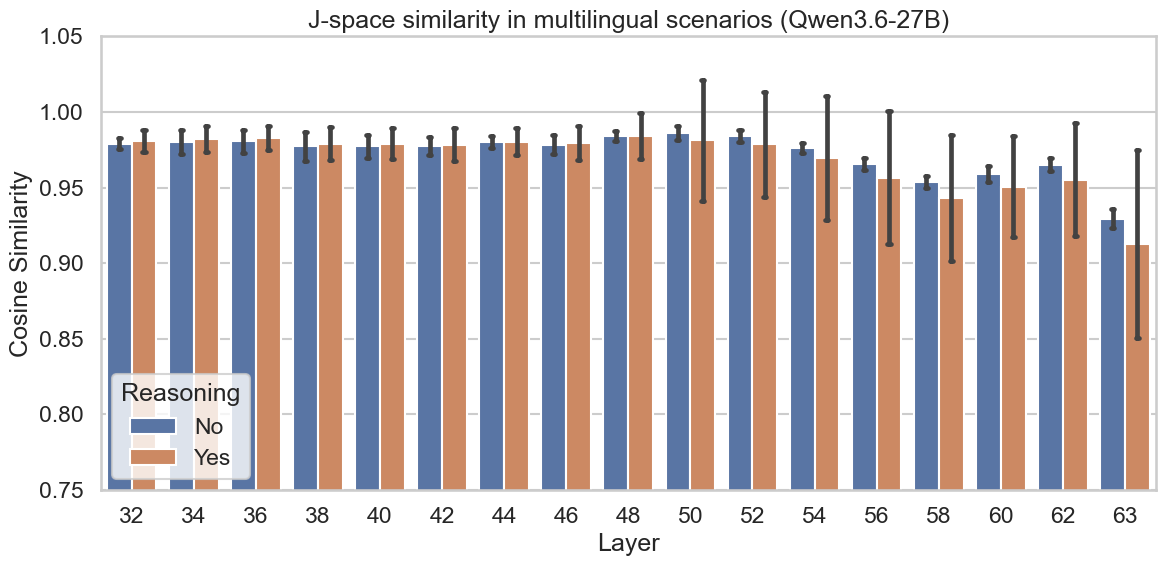

In [11]:
# Plot    
fig, ax = plt.subplots(figsize=(12, 6))

sns.barplot(
    data=df_combined,
    x="layer",
    y="cosine_similarity",
    hue="Reasoning",
    hue_order=["No", "Yes"],
    errorbar="sd",
    capsize=0.1,
    ax=ax,
)

ax.set_title(f"J-space similarity in multilingual scenarios ({MODEL_NAME})")
ax.set_xlabel("Layer")
ax.set_ylabel("Cosine Similarity")
ax.set_ylim(0.75, 1.05)

# if plot_legend:
# ax.legend(title="Scenario", loc="upper left", bbox_to_anchor=(1, 1))
# elif ax.get_legend() is not None:
    # ax.get_legend().remove()

plt.tight_layout()
plt.show()


## Multilingual lens

Compare similarity with and without multilinguage lens

In [65]:
# Baseline
# qwen
# df_multilang_lens = pd.read_csv(f"data/experiments/multilang/{MODEL_NAME}/single_250en_250es_lens.csv")
# gemma 3
df_original = pd.read_csv(f"data/experiments/multilang/{MODEL_NAME}/single_shared_layers.csv")
df_multilang_lens = pd.read_csv(f"data/experiments/multilang/{MODEL_NAME}/single_shared_layers_500en_500es_lens.csv")

In [ ]:
# Thinking
# qwen
# df_multilang_lens = pd.read_csv(f"data/experiments/multilang/{MODEL_NAME}/thinking_250en_250es_lens.csv")
# gemma
# df_multilang_lens = pd.read_csv(f"data/experiments/multilang/{MODEL_NAME}/thinking_500en_500es_lens.csv")

In [66]:
df_original['lens'] = 'original'
df_multilang_lens['lens'] = 'multilanguage'

print(df_original.layer.unique())
print(df_multilang_lens.layer.unique())

# HACK FOR NOW TO UNIFY LAYERS 
# df_multilang_lens.loc[:, 'layer'] = df_multilang_lens.layer.apply(lambda l:l+1 if l<41 else l)
# print(df_multilang_lens.layer.unique())

# From the baseline, select only the scenarios where the languages are different and the layers are common
layers_common = df_multilang_lens['layer'].unique()
df1 = df_original[(df_original['layer'].isin(layers_common)) & (~df_original.same_language)]

# df1.layer.unique()


df_combined = pd.concat([df1, df_multilang_lens], ignore_index=True)


[22 28 34 40 41]
[22 28 34 40 41]


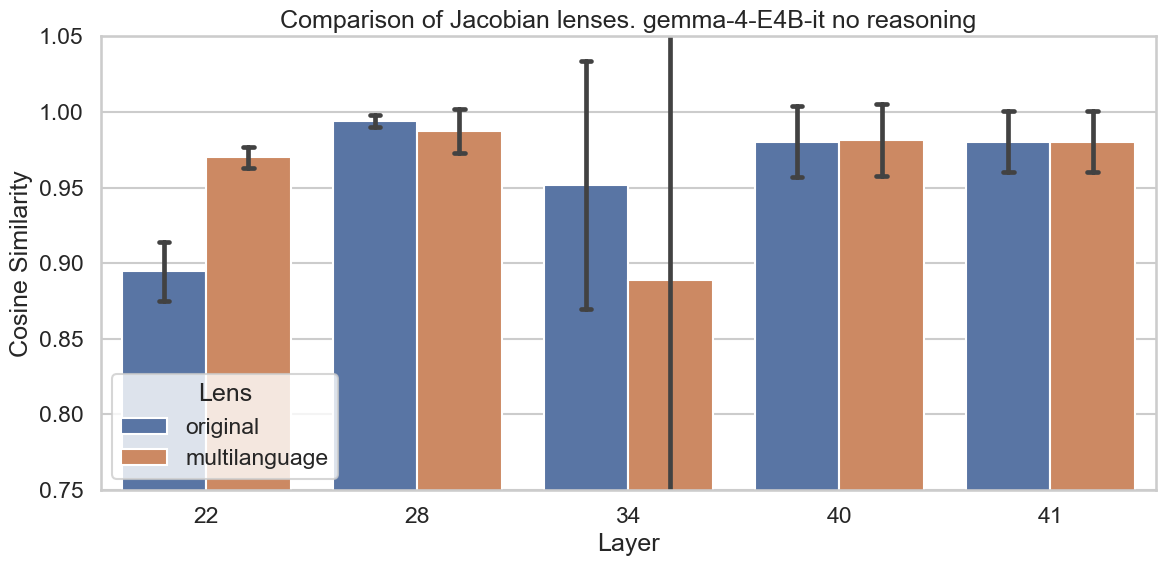

In [67]:
fig, ax = plt.subplots(figsize=(12, 6))

dff = df_combined

sns.barplot(
    data=dff,
    x="layer",
    y="cosine_similarity",
    hue="lens",
    errorbar="sd",
    capsize=0.1,
    ax=ax,
)

ax.set_title(f"Comparison of Jacobian lenses. {MODEL_NAME} no reasoning")
ax.set_xlabel("Layer")
ax.set_ylabel("Cosine Similarity")
ax.set_ylim(0.75, 1.05)
ax.legend(title="Lens")#, loc="lower left")

plt.tight_layout()
plt.show()

In [ ]:
# Combine the original and the multilens. The answers should be identical because we used the same seed
df_combined_2 = df_original.merge(df_multilang_lens, on = ['slug', 'scenario', 'layer'], suffixes=('_original', '_multilang'))

dff = df_combined_2[df_combined_2['same_answer_original'] != df_combined_2['same_answer_multilang']]
print(f"Number of different rows: {len(dff)}")

df_combined_2
# df_original[df_original['same_language']]['same_answer']

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))

dff = df_combined

# Create a combined colum for hue
def hue(row):
    suf = 'same_answer' if row['same_answer'] else 'different_answer'
    return f"{row['lens']}_{suf}"
dff['hue'] = dff.apply(hue, axis=1)

sns.barplot(
    data=dff,
    x="layer",
    y="cosine_similarity",
    hue="hue",
    errorbar="sd",
    capsize=0.1,
    ax=ax,
)

ax.set_title("Transported Residual Cosine Similarity by Layer (comparison of lenses)")
ax.set_xlabel("Layer")
ax.set_ylabel("Cosine Similarity")
ax.set_ylim(0.75, 1.05)
ax.legend(title="Lens")#, loc="lower left")

plt.tight_layout()
ax.legend(title="Lens - Same answer", loc="upper left", bbox_to_anchor=(1, 1))

plt.show()

In [ ]:
df_original[
    (~df_original['same_answer'])
    & (df_original['same_language'])
].sort_values(['slug', 'layer'])

In [ ]:
summary_df = (
    df_original.groupby(["layer", "same_language"], as_index=False)["cosine_similarity"]
    .agg(mean="mean", std="std", min="min", max="max", count="count")
    .sort_values(["same_language",  "layer", ])
)
summary_df

# Top-10 Word Overlap Across Layers and Lenses

In [ ]:
# Compare Top-10 Word Overlap by Scenario (Original vs. Multilanguage Lens)
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

for ax, (title, df_plot) in zip(
    axes,
    [("Original Lens", df_original), ("Multilanguage Lens (50/50)", df_multilang_lens)],
):
    sns.barplot(
        data=df_plot,
        x="layer",
        y="top_k_overlap_count",
        hue="scenario",
        errorbar="sd",
        capsize=0.1,
        ax=ax,
    )
    ax.set_title(f"Transported Top-10 Word Overlap by Layer ({title})")
    ax.set_xlabel("Layer")
    ax.set_ylabel("Shared Top-10 Words (Count)")
    ax.set_ylim(0, 10.5)
    ax.legend(title="Scenario")

plt.tight_layout()
plt.show()

In [ ]:
# Compare Cross-Lingual (en/es) Top-10 Word Overlap Across Original Lens, Multilanguage Lens, and Raw Logit Lens
df_raw_cross = df_original[~df_original.same_language].copy()
df_raw_cross["lens"] = "raw (no lens)"
df_raw_cross["top_k_overlap_count"] = df_raw_cross["raw_top_k_overlap_count"]
df_raw_cross["top_k_overlap_ratio"] = df_raw_cross["raw_top_k_overlap_ratio"]

df_overlap_comp = pd.concat([df_combined, df_raw_cross], ignore_index=True)

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=df_overlap_comp,
    x="layer",
    y="top_k_overlap_count",
    hue="lens",
    errorbar="sd",
    capsize=0.1,
    ax=ax,
)

ax.set_title("Cross-Lingual (en/es) Shared Top-10 Words by Layer")
ax.set_xlabel("Layer")
ax.set_ylabel("Shared Top-10 Words (Count)")
ax.set_ylim(0, 10.5)
ax.legend(title="Lens")

plt.tight_layout()
plt.show()

In [ ]:
# Inspect saved top-10 words and shared words for cross-lingual pairs
import json

cols_to_show = [
    "question_id",
    "layer",
    "lens",
    "top_k_overlap_count",
    "shared_top_k_tokens",
    "top_k_tokens_1",
    "top_k_tokens_2",
]

df_tokens_view = df_combined[cols_to_show].copy()
for col in ["shared_top_k_tokens", "top_k_tokens_1", "top_k_tokens_2"]:
    df_tokens_view[col] = df_tokens_view[col].apply(
        lambda s: ", ".join(json.loads(s)) if isinstance(s, str) else s
    )

df_tokens_view.sort_values(["question_id", "layer", "lens"]).head(20)